In [2]:
import kagglehub
import torch
import os
import random
from PIL import Image
from xml.dom import minidom
import xml.etree.ElementTree as ET

c:\Users\USER\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
### 캐글헙에서 데이터셋을 다운로드하고 데이터 파일을 불러올 수 있도록 저장 경로를 출력하는 코드


# Download latest version
path = kagglehub.dataset_download("devdgohil/the-oxfordiiit-pet-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\USER\.cache\kagglehub\datasets\devdgohil\the-oxfordiiit-pet-dataset\versions\2


In [ ]:
### 모델 학습에 사용할 장치를 자동으로 설정하는 코드
    # GPU 사용 가능하면 GPU, 사용 불가능이면 CPU


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
### 데이터셋이 저장된 경로를 확인 + 경로 내부에 어떤 파일이 있는지 확인하는 코드


print(path)

for item in os.listdir(path):
    # listdir : 지정된 폴더 안에 있는 파일과 폴더의 이름을 목록으로 가져옴
    
    print(item)

C:\Users\USER\.cache\kagglehub\datasets\devdgohil\the-oxfordiiit-pet-dataset\versions\2
annotations
images
pet.ipynb


In [ ]:
### 데이터셋의 모든 하위 폴더와 파일 구조를 탐색하는 코드


for root, dirs, files in os.walk(path):
    # os.walk : 폴더 안에 있는 파일과 하위 폴더를 단계별로 탐색
    # root : 탐색 중인 폴더의 경로
    # dirs : 폴더 안에 있는 하위 폴더 목록
    # files : 폴더 안에 있는 파일 목록
    
    print("\n폴더:", root)
    
    print("하위 폴더:", dirs)
    
    print("파일:", files[:5])


폴더: C:\Users\USER\.cache\kagglehub\datasets\devdgohil\the-oxfordiiit-pet-dataset\versions\2
하위 폴더: ['annotations', 'images']
파일: ['pet.ipynb']

폴더: C:\Users\USER\.cache\kagglehub\datasets\devdgohil\the-oxfordiiit-pet-dataset\versions\2\annotations
하위 폴더: ['annotations']
파일: []

폴더: C:\Users\USER\.cache\kagglehub\datasets\devdgohil\the-oxfordiiit-pet-dataset\versions\2\annotations\annotations
하위 폴더: ['trimaps', 'xmls']
파일: ['._trimaps', 'list.txt', 'README', 'test.txt', 'trainval.txt']

폴더: C:\Users\USER\.cache\kagglehub\datasets\devdgohil\the-oxfordiiit-pet-dataset\versions\2\annotations\annotations\trimaps
하위 폴더: []
파일: ['._Abyssinian_1.png', '._Abyssinian_10.png', '._Abyssinian_100.png', '._Abyssinian_101.png', '._Abyssinian_102.png']

폴더: C:\Users\USER\.cache\kagglehub\datasets\devdgohil\the-oxfordiiit-pet-dataset\versions\2\annotations\annotations\xmls
하위 폴더: []
파일: ['Abyssinian_1.xml', 'Abyssinian_10.xml', 'Abyssinian_100.xml', 'Abyssinian_101.xml', 'Abyssinian_102.xml']

폴더: C:\

In [ ]:
### 데이터셋에서 이미지 파일과 XML 파일이 저장된 경로를 지정 + 파일 개수를 확인하는 코드


image_path = os.path.join(path, "images", "images")
    # os.path.join : 폴더 경로와 파일 이름을 안전하게 연결해서 하나의 경로를 만듬
image_files = os.listdir(image_path)

xml_path = os.path.join(path, "annotations", "annotations", "xmls")
xml_files = os.listdir(xml_path)

print("이미지 개수:", len(image_files))
print("XML 개수:", len(xml_files))

이미지 개수: 7393
XML 개수: 3686


In [ ]:
### 이미지 파일과 XML 파일의 이름을 비교해 서로 일치하는 파일과 누락된 파일을 확인하는 코드


# 이미지 경로
image_path = os.path.join(path, "images", "images")

# XML 경로
xml_path = os.path.join(path, "annotations", "annotations", "xmls")

# JPG 이름에서 확장자 제거
jpg_names = {
    os.path.splitext(file)[0]
        #  os.path.splitext : 파일 경로에서 파일 이름과 학장자를 분리
    for file in os.listdir(image_path)
    if file.lower().endswith(".jpg")}
        # lower : 소문자로 바꿈
        # endswith : 문자열로 끝나는지 확인

# XML 이름에서 확장자 제거
xml_names = {
    os.path.splitext(file)[0]
    for file in os.listdir(xml_path)
    if file.lower().endswith(".xml")
}

# 비교
jpg_only = jpg_names - xml_names
xml_only = xml_names - jpg_names
both = jpg_names & xml_names

print("JPG 개수:", len(jpg_names))
print("XML 개수:", len(xml_names))
print("둘 다 존재:", len(both))
print("JPG만 존재:", len(jpg_only))
print("XML만 존재:", len(xml_only))

JPG 개수: 7390
XML 개수: 3686
둘 다 존재: 3686
JPG만 존재: 3704
XML만 존재: 0


In [ ]:
### XML 파일을 읽어 객체의 바운딩 박스 좌표가 이미지 크기에 맞는지 검사 + 잘못된 좌표나 이상치가 있는지 확인하는 코드


# XML 파일 찾기
xml_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".xml"):
            xml_files.append(os.path.join(root, file))

print("XML 파일 개수:", len(xml_files))


# 이상한 Bounding Box 저장
bad_boxes = []

for xml_file in xml_files:

    try:
        tree = ET.parse(xml_file)
        # XML 파일을 읽어서 트리 구조로 변환
            # parse : 파일을 읽고 구조를 분석
        root = tree.getroot()
        # XML 문서에서 가장 바깥쪽에 있는 최상위 태그를 불러옴
            # tree.getroot : 최상위 요소 가져오기

        # 이미지 크기
        width = int(root.find("size/width").text)
        height = int(root.find("size/height").text)

        # 객체 확인
        for obj in root.findall("object"):

            class_name = obj.find("name").text

            box = obj.find("bndbox")

            xmin = int(box.find("xmin").text)
            ymin = int(box.find("ymin").text)
            xmax = int(box.find("xmax").text)
            ymax = int(box.find("ymax").text)

            # 이상치 검사
            if (
                xmin < 0 or
                ymin < 0 or
                xmax > width or
                ymax > height or
                xmin >= xmax or
                ymin >= ymax
            ):
                bad_boxes.append({
                    "file": xml_file,
                    "class": class_name,
                    "width": width,
                    "height": height,
                    "xmin": xmin,
                    "ymin": ymin,
                    "xmax": xmax,
                    "ymax": ymax
                })

    except Exception as e:
        print("XML 읽기 오류:", xml_file)
        print(e)


print()
print("이상한 Bounding Box 개수:", len(bad_boxes))

XML 파일 개수: 3686

이상한 Bounding Box 개수: 0


In [ ]:
### XML 파일에서 객체의 클래스 이름을 확인하고 개수를 집계하는 코드


dog_count = 0
cat_count = 0

for xml_file_name in xml_files:
    xml_file = os.path.join(xml_path, xml_file_name)

    tree = ET.parse(xml_file)
    root = tree.getroot()

    object = root.find("object")
    name = object.find("name").text

    if name == "dog":
        dog_count += 1
    elif name == "cat":
        cat_count += 1

print("dog:", dog_count)
print("cat:", cat_count)

dog: 2498
cat: 1188


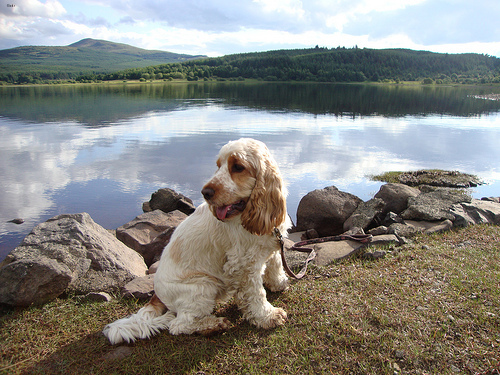

english_cocker_spaniel_74.jpg


In [ ]:
### 데이터셋에서 이미지를 무작위로 선택해 확인하는 코드


# 이미지 파일 중 하나를 랜덤으로 고른다.
random_image_file = random.choice(image_files)
# 이미지 파일의 경로를 만들고 이미지를 연다.
image = Image.open(os.path.join(image_path, random_image_file))

# 이미지를 화면에 보여준다.
display(image)
# 어떤 이미지를 보여준건지 확인한다.
print(random_image_file)

In [ ]:
### XML 파일을 랜덤으로 선택해 출력하는 코드


# XML 파일 중 하나를 랜덤으로 고른다.
random_xml_file = random.choice(os.listdir(xml_path))
# XML 파일의 경로를 만든다.
xml_file = os.path.join(xml_path, random_xml_file)

# XML 파일을 연다.
with open(xml_file, "r") as f:
    # XML 내용을 읽는다.
    xml_data = f.read()

# XML 내용을 보기 좋게 정리한다.
pretty_xml = minidom.parseString(xml_data).toprettyxml(indent="    ")

# XML 내용을 보여준다.
print(pretty_xml)

<?xml version="1.0" ?>
<annotation>
    <folder>OXIIIT</folder>
    <filename>leonberger_129.jpg</filename>
    <source>
        <database>OXFORD-IIIT Pet Dataset</database>
        <annotation>OXIIIT</annotation>
        <image>flickr</image>
    </source>
    <size>
        <width>333</width>
        <height>500</height>
        <depth>3</depth>
    </size>
    <segmented>0</segmented>
    <object>
        <name>dog</name>
        <pose>Frontal</pose>
        <truncated>0</truncated>
        <occluded>0</occluded>
        <bndbox>
            <xmin>140</xmin>
            <ymin>69</ymin>
            <xmax>253</xmax>
            <ymax>195</ymax>
        </bndbox>
        <difficult>0</difficult>
    </object>
</annotation>



In [ ]:
### XML 파일에서 이미지 이름, 객체의 클래스 이름, 바운딩 박스 좌표를 출력하는 코드
    # 객체가 이미지의 어느 위치에 있는지도 학습하기 위함


tree = ET.parse(xml_file)
root = tree.getroot()

# 이미지 이름
filename = root.find("filename").text
# 객체 이름
object = root.find("object")
name = object.find("name").text
# 바운딩 박스
box = object.find("bndbox")

xmin = int(box.find("xmin").text)
ymin = int(box.find("ymin").text)
xmax = int(box.find("xmax").text)
ymax = int(box.find("ymax").text)

print("이미지 이름:", filename)
print("객체 이름:", name)
print(xmin, ymin, xmax, ymax)

이미지 이름: leonberger_129.jpg
객체 이름: dog
140 69 253 195


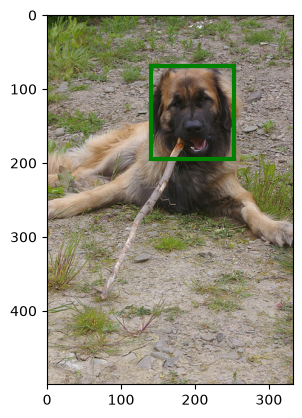

이미지 이름: leonberger_129.jpg


In [ ]:
### XML에서 추출한 바운딩 박스 시각화하는 코드
    # XML에 저장된 바운딩 박스 좌표가 실제 이미지 위치와 일치하는지 확인하기 위함


import matplotlib.pyplot as plt
import matplotlib.patches as patches

image = Image.open(os.path.join(image_path, filename))

plt.imshow(image)

box = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, edgecolor="green", linewidth=3)

plt.gca().add_patch(box)
plt.show()
print("이미지 이름:", filename)

In [ ]:
### 여러 파일을 확인하는 코드
    # 여러 파일을 확인해 일관된 형식으로 저장되어 있는지 확인하기 위함


for xml_file_name in xml_files[:3]:
    xml_file = os.path.join(xml_path, xml_file_name)

    tree = ET.parse(xml_file)
    root = tree.getroot()

    width = root.find("size/width").text
    height = root.find("size/height").text

    xmin = root.find("object/bndbox/xmin").text
    ymin = root.find("object/bndbox/ymin").text
    xmax = root.find("object/bndbox/xmax").text
    ymax = root.find("object/bndbox/ymax").text

    print("\nXML:", os.path.basename(xml_file))
    print("가로:", width)
    print("세로:", height)
    print("XMIN:", xmin, "/ YMIN:", ymin)
    print("XMAX:", xmax, "/ YMAX:", ymax)


XML: Abyssinian_1.xml
가로: 600
세로: 400
XMIN: 333 / YMIN: 72
XMAX: 425 / YMAX: 158

XML: Abyssinian_10.xml
가로: 375
세로: 500
XMIN: 72 / YMIN: 105
XMAX: 288 / YMAX: 291

XML: Abyssinian_100.xml
가로: 394
세로: 500
XMIN: 151 / YMIN: 71
XMAX: 335 / YMAX: 267


In [ ]:
### 기존 Train/Validation 후보 데이터를 Train과 Validation으로 8:2 비율로 분리하는 코드 + Test 데이터
    # 모델을 학습할 데이터, 점검할 데이터, 평가할 데이터를 구분하기 위함

from sklearn.model_selection import train_test_split

# 경로
annotations_path = os.path.join(path, "annotations", "annotations")

trainval_path = os.path.join(annotations_path, "trainval.txt")
test_path = os.path.join(annotations_path, "test.txt")

# trainval 읽기
with open(trainval_path, "r") as f:
    trainval_data = f.readlines()
        # f.readlines : 텍스트 파일의 모든 줄을 읽어서 리스트로 변환

# test 읽기
with open(test_path, "r") as f:
    test_data = f.readlines()

# 줄바꿈 제거
trainval_data = [x.strip() for x in trainval_data]
    # x.strip() : 문자열의 양쪽 끝에 있는 공백이나 줄바꿈 문자 등을 제거
test_data = [x.strip() for x in test_data]

# Train / Validation 분리
train_data, val_data = train_test_split(trainval_data, test_size=0.2, random_state=42)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Train: 2944
Validation: 736
Test: 3669


In [ ]:
### TrainVal 목록에 있는 데이터와 XML 파일이 실제로 존재하는지 확인하는 코드
    # 파일 누락으로 인한 오류를 방지하기 위함


valid_trainval_data = []

for data in trainval_data:

    file_name = data.split()[0]

    image_file = os.path.join(
        image_path,
        file_name + ".jpg"
    )

    xml_file = os.path.join(
        xml_path,
        file_name + ".xml"
    )

    if os.path.exists(image_file) and os.path.exists(xml_file):
        # os.path.exists : 지정된 경로에 파일/폴더가 존재하는지 확인
        valid_trainval_data.append(data)

print("기존 TrainVal:", len(trainval_data))
print("정상 TrainVal:", len(valid_trainval_data))

기존 TrainVal: 3680
정상 TrainVal: 3671


In [ ]:
### 모든 이미지의 가로/세로 크기를 확인 + 서로 다른 이미지 크기가 몇 종류인지 출력하는 코드
    # 크기가 다르면 학습하기 힘들기에 전처리가 필요한지 확인하기 위함


from PIL import Image

image_sizes = set()

for image_file in image_files:
    image = Image.open(os.path.join(image_path, image_file))
    image_sizes.add(image.size)

print("이미지 크기 종류:", len(image_sizes))

for size in sorted(image_sizes):
    print(size)

이미지 크기 종류: 1022
(114, 143)
(117, 200)
(119, 200)
(133, 200)
(137, 103)
(140, 134)
(144, 108)
(150, 112)
(150, 116)
(150, 200)
(154, 200)
(157, 202)
(161, 240)
(163, 300)
(164, 300)
(167, 250)
(173, 200)
(174, 175)
(174, 226)
(175, 186)
(176, 300)
(177, 300)
(180, 250)
(183, 275)
(184, 250)
(184, 300)
(189, 135)
(189, 300)
(190, 168)
(190, 285)
(190, 300)
(191, 188)
(191, 300)
(192, 288)
(194, 259)
(194, 316)
(197, 300)
(198, 300)
(198, 320)
(199, 300)
(200, 149)
(200, 150)
(200, 157)
(200, 172)
(200, 179)
(200, 182)
(200, 192)
(200, 195)
(200, 200)
(200, 239)
(200, 266)
(200, 289)
(200, 300)
(200, 314)
(201, 300)
(202, 300)
(203, 300)
(204, 300)
(205, 300)
(205, 320)
(206, 243)
(206, 300)
(207, 300)
(208, 269)
(208, 278)
(208, 300)
(209, 300)
(210, 240)
(210, 500)
(211, 300)
(212, 238)
(212, 300)
(214, 300)
(214, 320)
(215, 216)
(215, 300)
(216, 188)
(216, 280)
(216, 300)
(217, 300)
(218, 300)
(219, 300)
(220, 165)
(220, 220)
(220, 300)
(221, 300)
(221, 306)
(222, 300)
(223, 300)
(224,

In [28]:
import os
import xml.etree.ElementTree as ET

from PIL import Image
import torch
import numpy as np
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

In [ ]:
### 데이터셋의 이미지와 XML 파일을 불러와 SSD 모델이 학습 할 수 있는 형태로 변환하고 PetDataset 클래스를 정의하는 코드
    # 이미지뿐만 아니라 객체의 클래스와 바운딩 박스 좌표도 함께 학습해야함
    # 이미지와 XML에서 해당 정보를 추출 + 이미지와 정답 정보를 텐서로 변환해 모델에 전달
    # 클래스 라벨 지정 + 이미지와 좌표를 함께 관리해 객체 탐지 학습에 필요한 데이터 준비

class PetDataset(Dataset):

    def __init__(self, image_path, xml_path, data_list):

        self.image_path = image_path
        self.xml_path = xml_path
        self.data_list = data_list

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, index):

        file_name = self.data_list[index].split()[0]

        image_file = os.path.join(self.image_path, file_name + ".jpg")
        xml_file = os.path.join(self.xml_path, file_name + ".xml")

        image = Image.open(image_file).convert("RGB")

        original_width, original_height = image.size

        tree = ET.parse(xml_file)
        root = tree.getroot()

        boxes = []
        labels = []

        for obj in root.findall("object"):

            class_name = obj.find("name").text

            if class_name == "cat":
                label = 1
            else:
                label = 2

            box = obj.find("bndbox")

            xmin = int(box.find("xmin").text)
            ymin = int(box.find("ymin").text)
            xmax = int(box.find("xmax").text)
            ymax = int(box.find("ymax").text)

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(label)

        ### 기본 모델, dataset에서 resize를 정하면 사용하는 코드
        # new_width = 300
        # new_height = 300

        # image = image.resize((new_width, new_height))

        # scale_w = new_width / original_width
        # scale_h = new_height / original_height

        # new_boxes = []

        # for box in boxes:

        #     xmin, ymin, xmax, ymax = box

        #     xmin = xmin * scale_w
        #     xmax = xmax * scale_w

        #     ymin = ymin * scale_h
        #     ymax = ymax * scale_h

        #     new_boxes.append([xmin, ymin, xmax, ymax])

        image = np.array(image)
        image = torch.tensor(image, dtype=torch.float32)
        image = image.permute(2, 0, 1)
        image = image / 255.0

        ### 기본 모델, dataset에서 resize를 정하면 사용하는 코드
        # boxes = torch.tensor(new_boxes, dtype=torch.float32)
        
        boxes = torch.tensor(boxes, dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.int64)

        target = {"boxes": boxes, "labels": labels}

        return image, target

In [ ]:
### 이미지와 XML 파일 경로 지정 + 펫데이터셋 클래스를 이용해 트레인, 발리데이션, 테스트 데이터셋 객체를 생성하는 코드
    # 데이터를 학습용, 검증용, 테스트용으로 필요한 데이터를 불러올 수 있도록 준비하기 위함


image_path = os.path.join(path, "images", "images")
xml_path = os.path.join(path, "annotations", "annotations", "xmls")

train_dataset = PetDataset(image_path, xml_path, train_data)
val_dataset = PetDataset(image_path, xml_path, val_data)
test_dataset = PetDataset(image_path, xml_path, test_data)

In [ ]:
### 이미지 하나를 불러와 이미지 크기/픽셀값/바운딩박스 좌표/ 클래스 라벨이 맞는지 확인하는 코드
    # 학습 오류가 발생하거나 객체 탐지 성능이 낮아지지 않기 위함


image, target = train_dataset[0]

### SSD300 VGG16 test용
print("이미지 크기:", image.shape)
print("이미지 최솟값:", image.min())
print("이미지 최댓값:", image.max())

print("\n이미지:", image.size)
print("Bounding Box:", target["boxes"])
print("Class:", target["labels"])

이미지 크기: torch.Size([3, 333, 500])
이미지 최솟값: tensor(0.)
이미지 최댓값: tensor(1.)

이미지: <built-in method size of Tensor object at 0x0000011A82924980>
Bounding Box: tensor([[234.,  79., 454., 281.]])
Class: tensor([2])


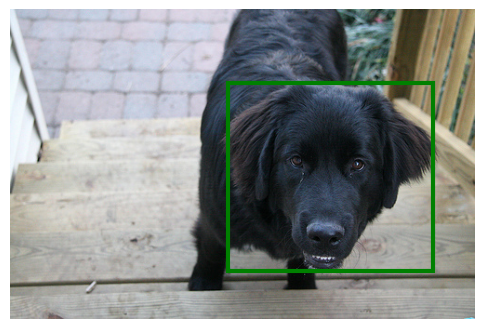

In [ ]:
### 트레인 데이터셋에서 이미지 하나를 가져와 시각화한 코드
    # 학습 전 데이터가 잘 처리되는지 확인하기 위함


import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Dataset에서 하나 가져오기
image, target = train_dataset[0]

# Tensor → 이미지 형태로 변경
image_show = image.permute(1, 2, 0)
    # image.permute : 이미지 텐서의 차원 순서 바꾸기
    # ex) 높이 -> 너비 -> 채널
    # 바꾼 후) 채널 -> 높이 -> 너비
    
# 이미지 출력
plt.figure(figsize=(6, 6))
plt.imshow(image_show)

# Bounding Box 그리기
for box in target["boxes"]:

    xmin, ymin, xmax, ymax = box

    width = xmax - xmin
    height = ymax - ymin

    rectangle = patches.Rectangle((xmin, ymin), width, height, fill=False, edgecolor="green", linewidth=3)

    plt.gca().add_patch(rectangle)

plt.axis("off")
plt.show()

In [ ]:
### collate_fn 함수를 정의해 정답 정보를 배치 단위로 묶고 데이터로드를 이용해
### 트레인/발리데이션/테스트 데이터를 모델에 전달할 수 있도록 준비하는 코드
    # 이미지마다 포함된 객체의 개수와 바운딩 박스 개수가 다를 수 있기 때문에
    # 이미지와 정답 정보를 리스트로 묶어 배치 단위로 전달하기 위함


def collate_fn(batch):

    images = []
    targets = []

    for image, target in batch:
        images.append(image)
        targets.append(target)

    ### 기본 모델, dataset에서 resize를 정하면 사용하는 코드
    # images = torch.stack(images)

    return images, targets

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, collate_fn=collate_fn)

In [ ]:
### 트레인로드에서 배치를 하나 가져와 이미지 개수와 정답 정보의 개수가 일치하는지
### 바운딩 박스 좌표와 클래스 라벨을 출력하는 코드
    # 배치 단위로 묶는 과정에서 잘 연결되어 있는지 확인하고 점검하기 위함


images, targets = next(iter(train_loader))

### 기본 모델, dataset에서 resize를 정하면 사용하는 코드
# print("이미지 크기:", images.shape)

print("이미지 개수:", len(images))
print("Target 개수:", len(targets))

for i in range(len(targets)):
    print(f"\n{i+1}번째 이미지")
    print("Bounding box", targets[i]["boxes"])
    print("Class:", targets[i]["labels"])

이미지 개수: 4
Target 개수: 4

1번째 이미지
Bounding box tensor([[244., 105., 345., 211.]])
Class: tensor([2])

2번째 이미지
Bounding box tensor([[ 85.,  48., 288., 239.]])
Class: tensor([2])

3번째 이미지
Bounding box tensor([[263.,  67., 358., 164.]])
Class: tensor([2])

4번째 이미지
Bounding box tensor([[129., 167., 231., 263.]])
Class: tensor([1])


In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models.detection import ssd300_vgg16
from torchvision.models.detection.ssd import SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

In [105]:
## 기존 Head

model = ssd300_vgg16(weights=SSD300_VGG16_Weights.DEFAULT)

num_classes = 3

print(model.head.classification_head)

print("\nnum_columns:")
print(model.head.classification_head.num_columns)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\n사용 장치:", device)

SSDClassificationHead(
  (module_list): ModuleList(
    (0): Conv2d(512, 364, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Conv2d(1024, 546, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): Conv2d(512, 546, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): Conv2d(256, 546, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4-5): 2 x Conv2d(256, 364, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)

num_columns:
91

사용 장치: cuda


In [106]:
### 기존 헤드에서 in_channels과 num_anchors을 추출하는 코드
    # 새로운 헤드를 만들때 호환이 잘 되게 하기 위함


in_channels = [layer.in_channels for layer in model.head.classification_head.module_list]
num_anchors = model.anchor_generator.num_anchors_per_location()

print("in_channels:", in_channels)
print("Anchor 개수:", num_anchors)

in_channels: [512, 1024, 512, 256, 256, 256]
Anchor 개수: [4, 6, 6, 6, 4, 4]


In [107]:
### 사전 학습된 SSD300 VGG16 모델을 불러오는 코드
    # 데이터에 맞게 고양이/강아지/배경 총 3개 클래스를 구분하기 위해 모델을 변경
    # 모델을 사용할 장치로 이동 + 학습과 예측을 진행할 수 있도록 준비


### 새로운 Head

model = ssd300_vgg16(weights=SSD300_VGG16_Weights.DEFAULT)

num_classes = 3

new_head = SSDClassificationHead(in_channels=in_channels, num_anchors=num_anchors, num_classes=num_classes)

model.head.classification_head = new_head

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print(model.head.classification_head)
print("클래스 수:", model.head.classification_head.num_columns)

print("\n사용 장치:", device)

SSDClassificationHead(
  (module_list): ModuleList(
    (0): Conv2d(512, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Conv2d(1024, 18, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): Conv2d(512, 18, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): Conv2d(256, 18, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4-5): 2 x Conv2d(256, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)
클래스 수: 3

사용 장치: cuda


In [108]:
### 트레인 데이터에서 배치 하나를 가져와 SSD 모델에 입력해 손실값을 확인하는 코드
    # 손실값이 잘 나오는지 확인하고 학습을 진행하기 전에 데이터 형식과 학습 단계가 잘 작동되는지 점검하기 위함


images, targets = next(iter(train_loader))

images = [image.to(device) for image in images]

targets = [{"boxes": target["boxes"].to(device),
            "labels": target["labels"].to(device)}
            for target in targets]

model.train()

loss_dict = model(images, targets)

print(loss_dict)

{'bbox_regression': tensor(2.0125, device='cuda:0', grad_fn=<DivBackward0>), 'classification': tensor(17.3369, device='cuda:0', grad_fn=<DivBackward0>)}


In [109]:
### SSD 모델의 학습 과정에서 가중치를 업데이트할 최적화 알고리즘으로 SGD를 설정 + 학습률과 모멘텀, 가중치 감쇠값을 지정하는 코드
    # 모델이 계산한 손실을 줄이는 방향으로 가중치를 조정해 객체 탐지 성능을 개선하기 위함


import torch.optim as optim

optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9, weight_decay=0.0005)

In [110]:
### 모델과 입력 데이터가 다른 장치에 있으면 오류가 발생하기 때문에 같은 장치로 이동하는 코드


images, targets = next(iter(train_loader))

images = [image.to(device) for image in images]

targets = [{"boxes": target["boxes"].to(device),
            "labels": target["labels"].to(device)}
            for target in targets]

In [111]:
### SSD 객체 탐지 모델의 트레인 학습 코드


num_epochs = 10

for epoch in range(num_epochs):

    model.train()

    total_loss = 0

    for images, targets in train_loader:

        images = [image.to(device) for image in images]

        targets = [{"boxes": target["boxes"].to(device),
                    "labels": target["labels"].to(device)}
                    for target in targets]

        optimizer.zero_grad()

        loss_dict = model(images, targets)

        loss = sum(loss_dict.values())

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(f"Epoch [{epoch + 1}/{num_epochs}]"
        f"Loss {average_loss:.4f}")

Epoch [1/10]Loss 3.1059
Epoch [2/10]Loss 1.8031
Epoch [3/10]Loss 1.3673
Epoch [4/10]Loss 1.0691
Epoch [5/10]Loss 0.8129
Epoch [6/10]Loss 0.6811
Epoch [7/10]Loss 0.5670
Epoch [8/10]Loss 0.4570
Epoch [9/10]Loss 0.3799
Epoch [10/10]Loss 0.3257


In [ ]:
### SSD 모델의 발리데이션 예측 결과와 실제 정답을 비교하는 코드


# 모델을 평가 모드로 변경
model.eval()

# 평가 시 기울기 계산 비활성화
with torch.no_grad():

    # Validation 데이터에서 배치 가져오기
    for images, targets in val_loader:

        # 이미지들을 GPU 또는 CPU로 이동
        images = [image.to(device) for image in images]

        # SSD 모델로 객체 탐지
        predictions = model(images)

        # 예측 개수 출력
        print("예측 개수:", len(predictions))

        # 첫 번째 이미지의 예측 결과 가져오기
        prediction = predictions[0]

        # Bounding Box 출력
        print("\nBounding Box:")
        print(prediction["boxes"])

        # Class 출력
        print("\nClass:")
        print(prediction["labels"])

        # Confidence 출력
        print("\nConfidence:")
        print(prediction["scores"])

        # 첫 번째 이미지의 실제 정답 출력
        print("\n실제 정답 Bounding Box:")
        print(targets[0]["boxes"])

        print("\n실제 정답 Class:")
        print(targets[0]["labels"])

        # 첫 번째 배치만 확인
        break

예측 개수: 4

Bounding Box:
tensor([[  8.6709,   9.6746, 328.4591, 361.7806]], device='cuda:0')

Class:
tensor([2], device='cuda:0')

Confidence:
tensor([0.9994], device='cuda:0')

실제 정답 Bounding Box:
tensor([[  8.,   1., 330., 376.]])

실제 정답 Class:
tensor([2])


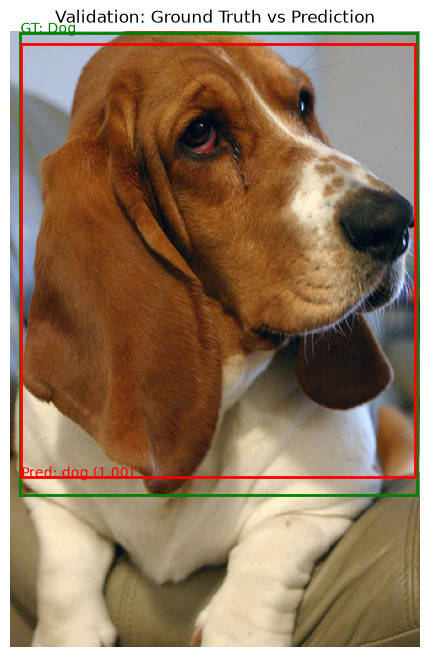

In [ ]:
### 발리데이션 데이터에서 실제 정답 바운딩 박스와 SSD 모델이 예측한 바운딩 박스를 이미지 시각화한 코드
    # 예측과 정답 박스 시각화


import matplotlib.pyplot as plt
import matplotlib.patches as patches

model.eval()

images, targets = next(iter(val_loader))

image = images[0]
target = targets[0]

input_image = image.to(device)

with torch.no_grad():

    prediction = model([input_image])[0]

image_np = image.permute(1, 2, 0).cpu().numpy()

fig, ax = plt.subplots(1, figsize=(10, 8))
ax.imshow(image_np)

for box, label in zip(target["boxes"], target["labels"]):

    x1, y1, x2, y2 = box.tolist()

    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="green", facecolor="none")

    ax.add_patch(rect)

    class_name = "Cat" if label.item() == 1 else "Dog"

    ax.text(x1, y1, f"GT: {class_name}", color="green", fontsize=10)

for box, label, score in zip(prediction["boxes"], prediction["labels"], prediction["scores"]):

    if score.item() < 0.5:
        continue

    x1, y1, x2, y2 = box.cpu().tolist()

    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="red", facecolor="none")

    ax. add_patch(rect)

    class_name = "Cat" if label.item() == 1 else "dog"

    ax.text(x1, y2, f"Pred: {class_name} ({score.item():.2f})", color="red", fontsize=10)

ax.set_title("Validation: Ground Truth vs Prediction")
ax.axis("off")
plt.show()

In [ ]:
### 학습한 SSD 객체 탐지 모델을 Validation 데이터로 평가하는 코드
    # Precision, Recall, F1-score, IoU 평가


from torchvision.ops import box_iou
import torch

# 평가 기준
score_threshold = 0.5
iou_threshold = 0.5
# 조건이 있기에 모든 조건의 모델 성능이 아니라 설정한 조건의 성능이다.

# 평가 결과를 저장할 변수 초기화
total_tp = 0
total_fp = 0
total_fn = 0
total_gt = 0
matched_ious = []

model.eval()

with torch.no_grad():
    for images, targets in val_loader:

        # 모델에 입력할 이미지를 GPU 또는 지정 장치로 이동
        images = [image.to(device) for image in images]

        # 이미지별 예측 결과
        predictions = model(images)

        # 배치 안의 이미지 각각 평가
        for prediction, target in zip(predictions, targets):
            # zip : 두 목록에서 같은 순서에 있는 학목을 짝지음

            pred_boxes = prediction["boxes"].cpu()
            pred_labels = prediction["labels"].cpu()
            pred_scores = prediction["scores"].cpu()

            gt_boxes = target["boxes"].cpu()
            gt_labels = target["labels"].cpu()

            # 전체 정답 객체 수 누적
            total_gt += len(gt_boxes)

            # Confidence 기준 적용
            keep = pred_scores >= score_threshold
            pred_boxes = pred_boxes[keep]
            pred_labels = pred_labels[keep]
            pred_scores = pred_scores[keep]

            # 예측 박스와 정답 박스의 IoU 계산
            iou_matrix = box_iou(pred_boxes, gt_boxes)
                # IoU : 예측한 바운딩 박스가 실제 객체 위치와 얼마나 겹치는지 평가

            matched_gt = set()
            image_tp = 0

            # Confidence가 높은 예측부터 정답과 매칭
            for pred_idx in torch.argsort(pred_scores, descending=True):
                # torch.argsort() : 값을 정렬했을때 몇번 째 위치에 있었는지 인덱스를 반환
                # descending=True : 큰 값부터 작은 값 순서로 정렬

                candidates = [gt_idx for gt_idx in range(len(gt_boxes))
                    if (pred_labels[pred_idx].item() == gt_labels[gt_idx].item()
                        # 클래스가 같은지 확인
                        and iou_matrix[pred_idx, gt_idx].item() >= iou_threshold
                        # IoU 값이 기준값 이상인지 확인 ( 0.5 이상인지 )
                        and gt_idx not in matched_gt)]
                        # 이미 매칭된 정답인지 확인

                if candidates:
                    best_gt = max(candidates, key=lambda idx: iou_matrix[pred_idx, idx].item())
                    # IoU가 가장 높은 정답 선택
                        # key : 무엇을 기준으로 가장 큰 항목을 찾을지 지정
                        # : lambda idx : idx라는 입력을 받아 간단한 계산을 수행하는 익명 함수

                    image_tp += 1
                    matched_gt.add(best_gt)

                    matched_ious.append(iou_matrix[pred_idx, best_gt].item())
                    # 매칭된 IoU 점수 저장

            # 이미지별 TP, FP, FN 계산
            image_fp = len(pred_boxes) - image_tp
            image_fn = len(gt_boxes) - image_tp

            total_tp += image_tp
            total_fp += image_fp
            total_fn += image_fn

# 최종 평가 지표
precision = total_tp / (total_tp + total_fp) \
    if total_tp + total_fp > 0 else 0

recall = total_tp / (total_tp + total_fn) \
    if total_tp + total_fn > 0 else 0

mean_iou = (sum(matched_ious) / len(matched_ious)
            if matched_ious else 0)

f1 = (2 * precision * recall / (precision + recall)
      if precision + recall > 0 else 0)

print("===== Validation 평가 결과 =====")
print(f"실제 객체 수: {total_gt}")
print(f"TP: {total_tp}")
print(f"FP: {total_fp}")
print(f"FN: {total_fn}")
print(f"평균 IoU (TP 기준): {mean_iou:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

===== Validation 평가 결과 =====
실제 객체 수: 736
TP: 713
FP: 31
FN: 23
평균 IoU (TP 기준): 0.8680
Precision: 0.9583
Recall: 0.9688
F1-score: 0.9635


In [ ]:
### 발리데이션 데이터에서 모델의 FP와 FN이 발생한 이미지를 찾아내는 코드
    # 바로 위 코드에서는 FP 31개, FN 23개 인데 이 코드 결과값은 39인 이유
    # FP와 FN은 객체의 개수이고 39는 오류가 발생한 이미지의 개수이기 때문에 다를 수 있다.
    # 39는 FP와 FN을 합한 숫자가 아니라 오탐이나 미탐이 발생한 이미지의 수이다.
    # ex) FP가 2개, FN이 1개 발생해도 오류 이미지에는 한 장만 추가된다.
    # 따라서 39장에 FP 31개와 FN 23개가 있다는 것이다.


import torch

score_threshold = 0.5
iou_threshold = 0.5

model.eval()

error_images = []

with torch.no_grad():
    for images, targets in val_loader:
        images = [image.to(device) for image in images]
        predictions = model(images)

        for image, target, prediction in zip(images, targets, predictions):
            gt_boxes = target["boxes"].to(device)
            gt_labels = target["labels"].to(device)

            pred_boxes = prediction["boxes"]
            pred_labels = prediction["labels"]
            pred_scores = prediction["scores"]

            # Confidence 기준을 통과한 예측만 남기기
            keep = pred_scores >= score_threshold
            pred_boxes = pred_boxes[keep]
            pred_labels = pred_labels[keep]
            pred_scores = pred_scores[keep]

            # 실제 정답 객체와 예측 객체 비교
            if len(gt_boxes) == 0 or len(pred_boxes) == 0:
                error_images.append({
                    "gt_count": len(gt_boxes),
                    "pred_count": len(pred_boxes),
                    "reason": "정답 또는 예측 객체가 없음"
                })
                continue

            ious = box_iou(pred_boxes, gt_boxes)

            # 각 정답 객체가 IoU 기준을 만족하는 예측을 갖는지 확인
            matched_gt = set()
            matched_pred = set()

            # IoU가 높은 순서대로 후보를 확인
            pairs = []
            for p in range(len(pred_boxes)):
                for g in range(len(gt_boxes)):
                    if pred_labels[p] == gt_labels[g] and ious[p, g] >= iou_threshold:
                        pairs.append((ious[p, g].item(), p, g))

            pairs.sort(reverse=True)

            for iou, p, g in pairs:
                if p not in matched_pred and g not in matched_gt:
                    matched_pred.add(p)
                    matched_gt.add(g)

            fp = len(pred_boxes) - len(matched_pred)
            fn = len(gt_boxes) - len(matched_gt)

            if fp > 0 or fn > 0:
                error_images.append({
                    "gt_count": len(gt_boxes),
                    "pred_count": len(pred_boxes),
                    "FP": fp,
                    "FN": fn
                })

print("오탐·미탐이 발생한 이미지 수:", len(error_images))
print("일부 사례:")
print(error_images[:10])

오탐·미탐이 발생한 이미지 수: 39
일부 사례:
[{'gt_count': 1, 'pred_count': 3, 'FP': 2, 'FN': 0}, {'gt_count': 1, 'pred_count': 2, 'FP': 1, 'FN': 0}, {'gt_count': 1, 'pred_count': 2, 'FP': 1, 'FN': 0}, {'gt_count': 1, 'pred_count': 0, 'reason': '정답 또는 예측 객체가 없음'}, {'gt_count': 1, 'pred_count': 2, 'FP': 1, 'FN': 0}, {'gt_count': 1, 'pred_count': 1, 'FP': 1, 'FN': 1}, {'gt_count': 1, 'pred_count': 1, 'FP': 1, 'FN': 1}, {'gt_count': 1, 'pred_count': 2, 'FP': 1, 'FN': 0}, {'gt_count': 1, 'pred_count': 1, 'FP': 1, 'FN': 1}, {'gt_count': 1, 'pred_count': 0, 'reason': '정답 또는 예측 객체가 없음'}]


In [ ]:
### SSD 객체 탐지 모델의 성능을 AP와 mAP 지표로 평가하는 코드
    # 객체를 찾는 정확도 + Confidence Score 순위와 바운딩 박스 위치까지 평가

    # AP@0.5 : 탐지하는 성능
    # mAP@0.5 : AP 평균
    # mAP@0.5:0.95 : IoU 기준을 0.50부터 0.95까지 바꾸어 평가한 AP들의 평균


import torch
from torchvision.ops import box_iou

def calculate_map(model, val_loader, device):
    model.eval()

    class_ids = [1, 2]  # Cat=1, Dog=2
    class_names = {1: "Cat", 2: "Dog"}

    # 이미지별 예측과 정답 저장
    all_predictions = []
    all_ground_truths = []
    gt_counts = {1: 0, 2: 0}

    with torch.no_grad():
        for image_id, (images, targets) in enumerate(val_loader):
            images = [image.to(device) for image in images]
            predictions = model(images)

            for target, prediction in zip(targets, predictions):
                gt_boxes = target["boxes"].cpu()
                gt_labels = target["labels"].cpu()

                pred_boxes = prediction["boxes"].cpu()
                pred_labels = prediction["labels"].cpu()
                pred_scores = prediction["scores"].cpu()

                # 정답 상자 저장
                for box, label in zip(gt_boxes, gt_labels):
                    label = int(label.item())
                    if label in class_ids:
                        all_ground_truths.append({
                            "image_id": image_id,
                            "box": box,
                            "label": label,
                            "matched": False
                        })
                        gt_counts[label] += 1

                # 예측 상자 저장: mAP 계산을 위해
                # Confidence 0.5 기준으로 미리 제거하지 않음
                for box, label, score in zip(
                    pred_boxes, pred_labels, pred_scores
                ):
                    label = int(label.item())
                    if label in class_ids:
                        all_predictions.append({
                            "image_id": image_id,
                            "box": box,
                            "label": label,
                            "score": float(score.item())
                        })

    def calculate_ap(class_id, iou_threshold):
        # 해당 클래스의 정답과 예측만 선택
        gt_by_image = {}
        for gt in all_ground_truths:
            if gt["label"] == class_id:
                gt_by_image.setdefault(gt["image_id"], []).append(gt)

        total_gt = gt_counts[class_id]

        if total_gt == 0:
            return float("nan")

        preds = [
            p for p in all_predictions
            if p["label"] == class_id
        ]
        preds.sort(key=lambda p: p["score"], reverse=True)

        # 각 IoU 기준에서 정답 매칭 상태 초기화
        for gt in all_ground_truths:
            if gt["label"] == class_id:
                gt["matched"] = False

        tp = []
        fp = []

        for pred in preds:
            candidates = gt_by_image.get(pred["image_id"], [])

            if not candidates:
                tp.append(0)
                fp.append(1)
                continue

            pred_box = pred["box"].unsqueeze(0)
            candidate_boxes = torch.stack(
                [gt["box"] for gt in candidates]
            )

            ious = box_iou(pred_box, candidate_boxes)[0]

            # IoU가 가장 높은 정답과 우선 매칭 시도
            order = torch.argsort(ious, descending=True)
            matched = False

            for idx in order.tolist():
                gt = candidates[idx]

                if (
                    ious[idx].item() >= iou_threshold
                    and not gt["matched"]
                ):
                    gt["matched"] = True
                    matched = True
                    break

            tp.append(1 if matched else 0)
            fp.append(0 if matched else 1)

        if len(tp) == 0:
            return 0.0

        tp = torch.tensor(tp, dtype=torch.float32).cumsum(0)
        fp = torch.tensor(fp, dtype=torch.float32).cumsum(0)

        recalls = tp / total_gt
        precisions = tp / (tp + fp).clamp(min=1e-8)

        # Precision-Recall 곡선 아래 면적(AP)
        mrec = torch.cat([
            torch.tensor([0.0]), recalls, torch.tensor([1.0])
        ])
        mpre = torch.cat([
            torch.tensor([0.0]), precisions, torch.tensor([0.0])
        ])

        for i in range(len(mpre) - 2, -1, -1):
            mpre[i] = torch.maximum(mpre[i], mpre[i + 1])

        changes = torch.where(mrec[1:] != mrec[:-1])[0]

        ap = torch.sum(
            (mrec[changes + 1] - mrec[changes])
            * mpre[changes + 1]
        ).item()

        return ap

    # IoU=0.5 기준 클래스별 AP
    ap50 = {}
    for class_id in class_ids:
        ap50[class_id] = calculate_ap(class_id, 0.5)

    # IoU=0.50, 0.55, ..., 0.95 기준
    iou_thresholds = [
        round(x / 100, 2) for x in range(50, 96, 5)
    ]

    ap_by_iou = {}
    for threshold in iou_thresholds:
        ap_by_iou[threshold] = {
            class_id: calculate_ap(class_id, threshold)
            for class_id in class_ids
        }

    # 클래스별 AP 평균
    map50 = sum(ap50.values()) / len(class_ids)

    # 모든 IoU 기준과 클래스를 평균
    map5095 = sum(
        ap_by_iou[t][c]
        for t in iou_thresholds
        for c in class_ids
    ) / (len(iou_thresholds) * len(class_ids))

    print("===== Validation mAP 평가 =====")
    for class_id in class_ids:
        print(f"{class_names[class_id]} AP@0.5: {ap50[class_id]:.4f}")

    print(f"\nmAP@0.5: {map50:.4f}")
    print(f"mAP@0.5:0.95: {map5095:.4f}")

    return map50, map5095, ap50, ap_by_iou


map50, map5095, ap50, ap_by_iou = calculate_map(
    model, val_loader, device
)


===== Validation mAP 평가 =====
Cat AP@0.5: 0.9754
Dog AP@0.5: 0.9762

mAP@0.5: 0.9758
mAP@0.5:0.95: 0.7273


In [ ]:
### 데이터셋에서 Test용 이미지를 불러오고 SSD 모델에 입력할 수 있는 형태로 전처리하는 사용자 정의 데이터셋 클래스
    # XML과 해당 이미지들의 정답 파일이 연결되어 있지 않은 관계로 새로운 Test용 데이터셋을 만듬

    # XML 폴더에서 해당 이미지들의 정답 바운딩 박스 파일이 연결되어 있지 않다고 뜸
    # 그래서 정답과 비교하는 실제 성능 평가를 할 수 없음
    # 왜 연결되어 있지 않은지와 어떻게 연결해야하는지 모르겠음
    # 그래서 일단 성능 평가는 못하지만 예측은 할 수 있다고해서 Test용 데이터셋을 새로 만듬
    # 맞는 방향인지는 잘 모르겠음


import os
import numpy as np
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader


class PetTestDataset(Dataset):

    def __init__(self, image_path, data_list):
        self.image_path = image_path
        self.data_list = data_list

        # 실제 이미지 파일이 존재하는 데이터만 저장
        self.valid_data = []

        for item in self.data_list:
            file_name = item.split()[0]

            image_file = os.path.join(
                self.image_path,
                file_name + ".jpg"
            )

            if os.path.isfile(image_file):
                self.valid_data.append(file_name)

        print("기존 Test 데이터:", len(self.data_list))
        print("사용 가능한 Test 이미지:", len(self.valid_data))

    def __len__(self):
        # 사용 가능한 이미지 개수 반환
        return len(self.valid_data)

    def __getitem__(self, index):

        # 이미지 파일 이름
        file_name = self.valid_data[index]

        # 이미지 경로
        image_file = os.path.join(
            self.image_path,
            file_name + ".jpg"
        )

        # 이미지 열기
        image = Image.open(image_file).convert("RGB")

        # NumPy 배열을 PyTorch 텐서로 변환
        image = np.array(image)
        image = torch.tensor(image, dtype=torch.float32)

        # [높이, 너비, 채널]을 [채널, 높이, 너비]로 변경
        image = image.permute(2, 0, 1)

        # 픽셀 값을 0~255에서 0~1 범위로 변환
        image = image / 255.0

        # 이미지와 파일 이름 반환
        return image, file_name

In [ ]:
### 새로운 Test용 데이터셋을 배치 단위로 불러와 SSD 모델이 예측할 수 있도록 준비하는 코드
    # 이유는 잘 모르지만 성능 평가는 아니고 예측만을 위한 준비 단계


def test_collate_fn(batch):

    images = []
    file_names = []

    for image, file_name in batch:
        images.append(image)
        file_names.append(file_name)

    return images, file_names


test_dataset = PetTestDataset(
    image_path=image_path,
    data_list=test_data
)

test_pred_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=test_collate_fn
)

기존 Test 데이터: 3669
사용 가능한 Test 이미지: 3669


In [ ]:
### Test 이미지 전체를 SSD 모델에 입력하고 예측 결과를 저장한 뒤 이미지의 결과를 확인하는 코드
    # Test 이미지에는 정답 XML이 없음...?? 모름 왜인지 모름
    # 그래서 성능 평가가 아님 그냥 예측만 함


# 모델 평가 모드
model.eval()

# 예측 결과와 파일 이름 저장
all_predictions = []
all_file_names = []

# 기울기 계산 없이 예측
with torch.no_grad():

    for images, file_names in test_pred_loader:

        # 이미지를 GPU 또는 CPU로 이동
        images = [
            image.to(device)
            for image in images
        ]

        # SSD 객체 탐지
        predictions = model(images)

        # 결과 저장
        all_predictions.extend(predictions)
        all_file_names.extend(file_names)


# 전체 예측 결과 확인
print("예측 이미지 수:", len(all_predictions))

if len(all_predictions) > 0:

    prediction = all_predictions[0]

    print("\n파일 이름:")
    print(all_file_names[0])

    print("\nBounding Box:")
    print(prediction["boxes"])

    print("\nClass:")
    print(prediction["labels"])

    print("\nConfidence:")
    print(prediction["scores"])

예측 이미지 수: 3669

파일 이름:
Abyssinian_201

Bounding Box:
tensor([[ 94.2622,  84.5923, 163.4722, 149.2037]], device='cuda:0')

Class:
tensor([1], device='cuda:0')

Confidence:
tensor([0.9999], device='cuda:0')


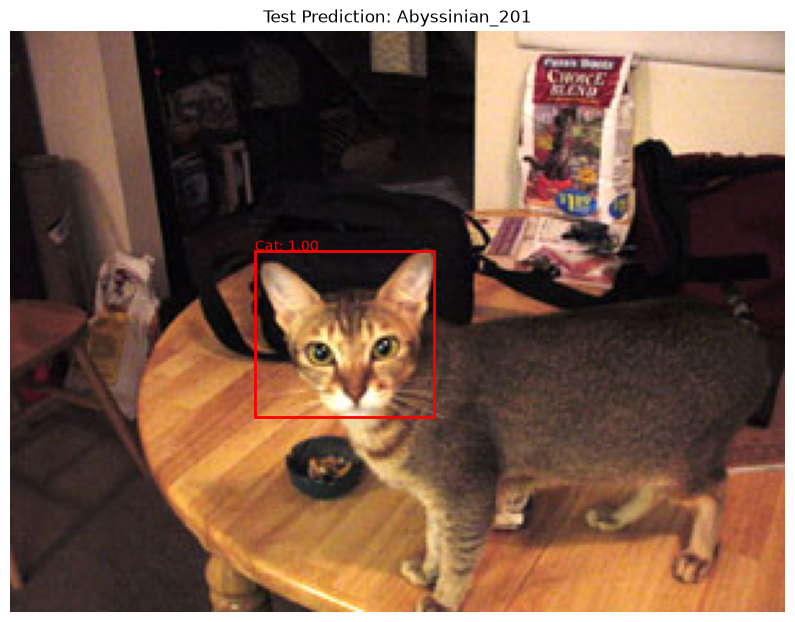

In [ ]:
### Test 이미지 한 장에 SSD 모델이 "예측"한 바운딩 박스, 클래스 이름, Confidence를 시각화한 코드
    # 예측이 잘 된건지 이미지 한장을 뽑아서 시각화함


import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 모델을 평가 모드로 변경
model.eval()

# Test 데이터에서 첫 번째 배치 가져오기
images, file_names = next(iter(test_pred_loader))

# 첫 번째 이미지 선택
image = images[0]
file_name = file_names[0]

# 모델 입력 이미지를 GPU 또는 CPU로 이동
input_image = image.to(device)

# 기울기 계산 없이 객체 탐지
with torch.no_grad():
    prediction = model([input_image])[0]

# 이미지 텐서를 시각화용 NumPy 배열로 변환
image_np = image.permute(1, 2, 0).cpu().numpy()

# 이미지 출력 영역 생성
fig, ax = plt.subplots(1, figsize=(10, 8))
ax.imshow(image_np)

# 예측 Bounding Box 표시
for box, label, score in zip(
    prediction["boxes"],
    prediction["labels"],
    prediction["scores"]
):

    # Confidence가 0.5 미만이면 표시하지 않음
    if score.item() < 0.5:
        continue

    # Bounding Box 좌표 가져오기
    x1, y1, x2, y2 = box.cpu().tolist()

    # 사각형 생성
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    # 이미지 위에 사각형 추가
    ax.add_patch(rect)

    # 클래스 번호를 이름으로 변환
    class_name = "Cat" if label.item() == 1 else "Dog"

    # 클래스와 Confidence 표시
    ax.text(
        x1,
        y1,
        f"{class_name}: {score.item():.2f}",
        color="red",
        fontsize=10
    )

# 제목과 축 설정
ax.set_title(f"Test Prediction: {file_name}")
ax.axis("off")

plt.show()

In [ ]:
### 발리데이션 성능을 평가하는 코드
    # 정확한 이유를 모르지만 Test가 성능을 평가하지 못하고 예측만 가능하다. (이유를 모름)
    # 그래서 어쩔 수 없이 validation의 성능 평가로 확인한다.
    # 평가했던 것을 한번에 보기 위한 코드


import torch
from torchvision.ops import box_iou

# ==========================================
# 1. 평가 설정
# ==========================================
score_threshold = 0.5
iou_threshold = 0.5

class_ids = [1, 2]  # 1 = Cat, 2 = Dog
class_names = {1: "Cat", 2: "Dog"}

model.eval()

# 이미지별 정답 및 예측 저장
all_gts = []
all_preds = []
image_id = 0

# ==========================================
# 2. Validation 예측 수집
# ==========================================
with torch.no_grad():
    for images, targets in val_loader:
        images = [img.to(device) for img in images]
        predictions = model(images)

        for target, prediction in zip(targets, predictions):
            gt_boxes = target["boxes"].cpu()
            gt_labels = target["labels"].cpu()

            pred_boxes = prediction["boxes"].cpu()
            pred_labels = prediction["labels"].cpu()
            pred_scores = prediction["scores"].cpu()

            # 실제 정답 저장
            for box, label in zip(gt_boxes, gt_labels):
                label = int(label.item())
                if label in class_ids:
                    all_gts.append({
                        "image_id": image_id,
                        "box": box,
                        "label": label
                    })

            # 모든 예측 저장
            # mAP 계산에서는 score_threshold로 미리 제거하지 않음
            for box, label, score in zip(
                pred_boxes, pred_labels, pred_scores
            ):
                label = int(label.item())
                if label in class_ids:
                    all_preds.append({
                        "image_id": image_id,
                        "box": box,
                        "label": label,
                        "score": float(score.item())
                    })

            image_id += 1

print("Validation 이미지 수:", image_id)
print("실제 정답 객체 수:", len(all_gts))
print("전체 예측 객체 수:", len(all_preds))


# ==========================================
# 3. TP, FP, FN 및 평균 IoU 계산
# ==========================================
def match_predictions(preds, gts, score_thr, iou_thr):
    # Confidence 기준 적용
    selected = [p for p in preds if p["score"] >= score_thr]
    selected.sort(key=lambda p: p["score"], reverse=True)

    # 이미지별 정답 분류
    gt_by_image = {}
    for gt in gts:
        gt_by_image.setdefault(gt["image_id"], []).append(gt)

    # 정답 객체의 중복 매칭 방지
    matched_gt = set()
    tp = 0
    fp = 0
    matched_ious = []

    for pred in selected:
        candidates = gt_by_image.get(pred["image_id"], [])

        # 같은 클래스의 정답만 후보로 사용
        candidates = [
            (idx, gt) for idx, gt in enumerate(candidates)
            if gt["label"] == pred["label"]
        ]

        if not candidates:
            fp += 1
            continue

        candidate_boxes = torch.stack(
            [gt["box"] for _, gt in candidates]
        )
        ious = box_iou(
            pred["box"].unsqueeze(0), candidate_boxes
        )[0]

        # 이미 매칭된 정답은 제외하고 가장 높은 IoU 선택
        order = torch.argsort(ious, descending=True)
        found = False

        for j in order.tolist():
            gt_index, gt = candidates[j]
            key = (pred["image_id"], id(gt))

            if (
                ious[j].item() >= iou_thr
                and key not in matched_gt
            ):
                matched_gt.add(key)
                matched_ious.append(ious[j].item())
                tp += 1
                found = True
                break

        if not found:
            fp += 1

    fn = len(gts) - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    mean_iou = (
        sum(matched_ious) / len(matched_ious)
        if matched_ious else 0.0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Mean IoU": mean_iou
    }


# ==========================================
# 4. AP 계산 함수
# ==========================================
def calculate_ap(class_id, iou_thr):
    class_gts = [
        gt for gt in all_gts if gt["label"] == class_id
    ]
    class_preds = [
        p for p in all_preds if p["label"] == class_id
    ]

    total_gt = len(class_gts)

    if total_gt == 0:
        return float("nan")

    # Confidence가 높은 예측부터 평가
    class_preds.sort(key=lambda p: p["score"], reverse=True)

    gt_by_image = {}
    for gt in class_gts:
        gt_by_image.setdefault(gt["image_id"], []).append(gt)

    matched = set()
    tp_list = []
    fp_list = []

    for pred in class_preds:
        candidates = gt_by_image.get(pred["image_id"], [])

        if not candidates:
            tp_list.append(0)
            fp_list.append(1)
            continue

        ious = box_iou(
            pred["box"].unsqueeze(0),
            torch.stack([gt["box"] for gt in candidates])
        )[0]

        order = torch.argsort(ious, descending=True)
        found = False

        for j in order.tolist():
            gt = candidates[j]
            key = (pred["image_id"], id(gt))

            if (
                ious[j].item() >= iou_thr
                and key not in matched
            ):
                matched.add(key)
                found = True
                break

        tp_list.append(1 if found else 0)
        fp_list.append(0 if found else 1)

    if not tp_list:
        return 0.0

    tp_cum = torch.tensor(tp_list, dtype=torch.float64).cumsum(0)
    fp_cum = torch.tensor(fp_list, dtype=torch.float64).cumsum(0)

    recalls = tp_cum / total_gt
    precisions = tp_cum / (tp_cum + fp_cum).clamp(min=1e-12)

    # Precision-Recall 곡선의 면적 계산
    mrec = torch.cat([
        torch.tensor([0.0], dtype=torch.float64),
        recalls,
        torch.tensor([1.0], dtype=torch.float64)
    ])
    mpre = torch.cat([
        torch.tensor([0.0], dtype=torch.float64),
        precisions,
        torch.tensor([0.0], dtype=torch.float64)
    ])

    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = torch.maximum(mpre[i], mpre[i + 1])

    changes = torch.where(mrec[1:] != mrec[:-1])[0]

    ap = torch.sum(
        (mrec[changes + 1] - mrec[changes])
        * mpre[changes + 1]
    )

    return ap.item()


# ==========================================
# 5. 전체 Precision, Recall, F1, IoU
# ==========================================
metrics = match_predictions(
    all_preds, all_gts,
    score_threshold, iou_threshold
)

print("\n===== Validation 기본 평가 =====")
print(f"Confidence 기준: {score_threshold}")
print(f"IoU 기준: {iou_threshold}")
print("실제 객체 수:", len(all_gts))

for name, value in metrics.items():
    if name in ["TP", "FP", "FN"]:
        print(f"{name}: {value}")
    else:
        print(f"{name}: {value:.4f} ({value * 100:.2f}%)")


# ==========================================
# 6. 클래스별 AP@0.5 및 mAP@0.5
# ==========================================
ap50 = {}

print("\n===== 클래스별 AP@0.5 =====")

for class_id in class_ids:
    ap50[class_id] = calculate_ap(class_id, 0.5)
    print(f"{class_names[class_id]} AP@0.5: {ap50[class_id]:.4f}")

valid_ap50 = [v for v in ap50.values() if v == v]
map50 = sum(valid_ap50) / len(valid_ap50) if valid_ap50 else 0.0

print(f"mAP@0.5: {map50:.4f}")


# ==========================================
# 7. mAP@0.5:0.95 계산
# ==========================================
iou_thresholds = [
    round(x / 100, 2) for x in range(50, 96, 5)
]

all_aps = []

for threshold in iou_thresholds:
    for class_id in class_ids:
        ap = calculate_ap(class_id, threshold)

        if ap == ap:  # NaN 제외
            all_aps.append(ap)

map5095 = sum(all_aps) / len(all_aps) if all_aps else 0.0

print(f"mAP@0.5:0.95: {map5095:.4f}")

print("\n===== 평가 완료 =====")


Validation 이미지 수: 735
실제 정답 객체 수: 736
전체 예측 객체 수: 1138

===== Validation 기본 평가 =====
Confidence 기준: 0.5
IoU 기준: 0.5
실제 객체 수: 736
TP: 713
FP: 31
FN: 23
Precision: 0.9583 (95.83%)
Recall: 0.9688 (96.88%)
F1-score: 0.9635 (96.35%)
Mean IoU: 0.8680 (86.80%)

===== 클래스별 AP@0.5 =====
Cat AP@0.5: 0.9754
Dog AP@0.5: 0.9790
mAP@0.5: 0.9772
mAP@0.5:0.95: 0.7279

===== 평가 완료 =====
